In [1]:
import requests
import pandas as pd

url = "https://archive-api.open-meteo.com/v1/archive"
params = {
    "latitude": 52.23,       # Warszawa
    "longitude": 21.01,
    "start_date": "2026-10-01",
    "end_date": "2026-10-07",
    "hourly": "temperature_2m",
    "timezone": "UTC",
}
r = requests.get(url, params=params, timeout=30)
r.raise_for_status()          # jeśli serwer zwróci błąd, od razu go zobaczymy
data = r.json()

weather = pd.DataFrame({
    "time": pd.to_datetime(data["hourly"]["time"], utc=True),
    "temp": data["hourly"]["temperature_2m"],
})
weather.head()

,time,temp
0,2026-10-01 00:00:00+00:00,12.0
1,2026-10-01 01:00:00+00:00,11.7
2,2026-10-01 02:00:00+00:00,11.2
3,2026-10-01 03:00:00+00:00,10.9
4,2026-10-01 04:00:00+00:00,10.5


In [2]:
import matplotlib.pyplot as plt

df = pd.read_parquet("../data/raw/kse_load.parquet")

# 1) Zostawiamy tylko tydzień 1–7.10.2026
bd = pd.to_datetime(df["business_date"])
week = df[bd.between("2026-10-01", "2026-10-07")].copy()

# 2) dtime_utc to KONIEC kwadransa, cofamy o 15 min, żeby mieć jego początek
week["start_utc"] = pd.to_datetime(week["dtime_utc"], utc=True) - pd.Timedelta(minutes=15)

# 3) 4 kwadranse -> 1 godzina (średnia)
load_h = (week.set_index("start_utc")["load_actual"]
              .resample("h").mean()
              .rename("load"))

# 4) Łączymy z pogodą po godzinie
merged = weather.set_index("time").join(load_h)
merged.head()

,temp,load
time,,
2026-10-01 00:00:00+00:00,12.0,14556.77375
2026-10-01 01:00:00+00:00,11.7,14616.65450
2026-10-01 02:00:00+00:00,11.2,14913.03900
2026-10-01 03:00:00+00:00,10.9,16092.19100
2026-10-01 04:00:00+00:00,10.5,18534.32650


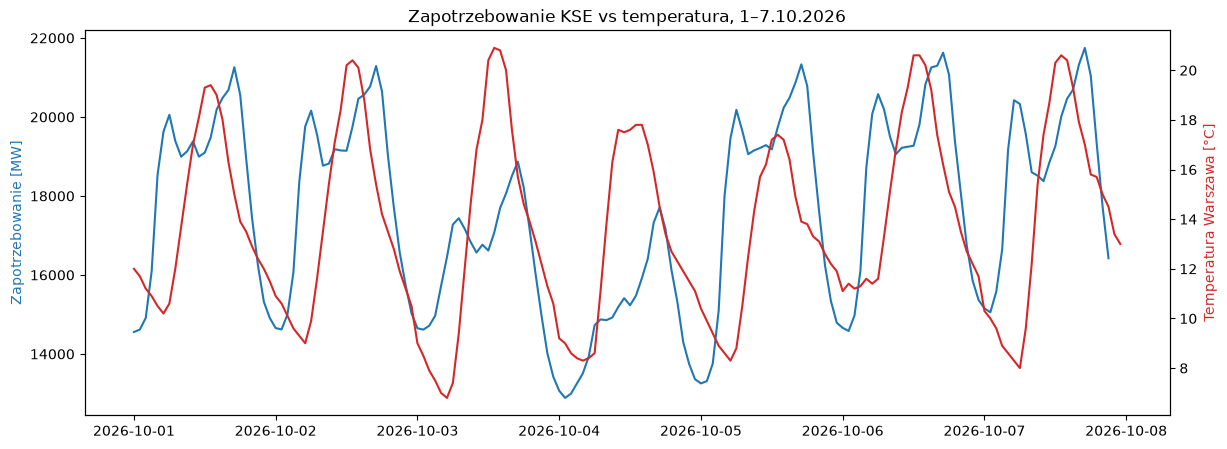

Korelacja: 0.5


In [3]:
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(merged.index, merged["load"], color="tab:blue", label="Zapotrzebowanie [MW]")
ax.set_ylabel("Zapotrzebowanie [MW]", color="tab:blue")

ax2 = ax.twinx()   # druga oś Y po prawej, bo MW i °C mają zupełnie inne skale
ax2.plot(merged.index, merged["temp"], color="tab:red", label="Temperatura [°C]")
ax2.set_ylabel("Temperatura Warszawa [°C]", color="tab:red")

ax.set_title("Zapotrzebowanie KSE vs temperatura, 1–7.10.2026")
plt.show()

print("Korelacja:", merged["load"].corr(merged["temp"]).round(2))